[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_01/MFM_ch1_volatility_clustering/MFM_ch1_volatility_clustering.ipynb)

# MFM_ch1_volatility_clustering

Volatility clustering and long memory: AutoCorrelation Function (ACF) of returns, absolute and squared returns for the S&P 500, slow decay of the ACF of absolute returns across markets, 63-day rolling volatility and the Taylor effect.

*Modelling Financial Markets (MFM), Chapter 1: Stylised Facts and Returns. Author: Daniel Traian Pele.*

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'

ASSETS = ['sp500', 'bettr', 'btc', 'eurron', 'gold']
COLORS = {'sp500': MainBlue, 'bettr': IDAred, 'btc': Amber, 'eurron': Forest, 'gold': Purple}
PERIODS = {'sp500': 252, 'bettr': 252, 'btc': 365, 'eurron': 252, 'gold': 252}


def save_fig(name):
    """Save the figure as PDF and transparent PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


## Data

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')

SOURCES = {
    'sp500':  ('GSPC.INDX',    'close', '1990-01-01'),
    'bettr':  ('BETTR.INDX',   'close', '2014-09-01'),
    'btc':    ('BTC-USD.CC',   'close', '2014-09-17'),
    'eurron': ('REF:EUR',      'close', '2005-07-01'),   # from the introduction of the new leu (RON), 1 July 2005
    'gold':   ('XAUUSD.FOREX', 'close', '1990-01-01'),
}

LABELS = {'sp500': 'S&P 500', 'bettr': 'BET-TR (Romania)', 'btc': 'Bitcoin',
          'eurron': 'EUR/RON', 'gold': 'Gold'}

# OTC quotes (gold): partial Saturday/Sunday sessions break the Friday -> Monday return,
# so we keep weekdays only (the same convention as in Chapter 0)
WEEKDAYS_ONLY = {'gold'}

_CACHE = {}


def read_market(symbol):
    """Read the daily price table of one symbol (local copy or GitHub)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    df = pd.read_csv(src, parse_dates=['date']).set_index('date').sort_index()
    df.index.name = 'Date'
    return df


def read_reference_rate(currency='EUR', start='2005-07-01', end='2026-09-18'):
    """Official RON reference rate (BNR annual XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    import re
    import urllib.request
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    df = pd.DataFrame(rows, columns=['Date', 'Close']).drop_duplicates('Date').set_index('Date')
    df.index = pd.to_datetime(df.index)
    _CACHE[key] = df.sort_index().loc[start:end]
    return _CACHE[key]


def load_data(name='sp500'):
    """Daily OHLCV with columns Open/High/Low/Close/Volume (Close = the price used)."""
    symbol, col, start = SOURCES[name]
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start)
    d = read_market(symbol).loc[start:]
    if name in WEEKDAYS_ONLY:
        d = d[d.index.dayofweek < 5]
    out = pd.DataFrame({'Open': d['open'], 'High': d['high'], 'Low': d['low'],
                        'Close': d[col], 'Volume': d['volume']})
    return out[out['Close'] > 0].dropna(subset=['Close'])


def load_close(name):
    """Closing price, used in all charts."""
    return load_data(name)['Close'].dropna()


closes = {a: load_close(a) for a in ASSETS}
rets = {a: np.log(c).diff().dropna() for a, c in closes.items()}
# gold (weekdays only) is annualised with its actual number of observations per year
PERIODS['gold'] = len(rets['gold']) / ((closes['gold'].index[-1] - closes['gold'].index[0]).days / 365.25)
spx_ohlc = load_data('sp500')
for a in ASSETS:
    print(f'{LABELS[a]:18s}', rets[a].index[0].date(), '->', rets[a].index[-1].date(), len(rets[a]), 'obs')

S&P 500            1990-01-03 -> 2026-09-18 9245 obs
BET-TR (Romania)   2014-09-24 -> 2026-09-18 2992 obs
Bitcoin            2014-09-18 -> 2026-09-18 4384 obs
EUR/RON            2005-07-05 -> 2026-09-18 5352 obs
Gold               1990-01-03 -> 2026-09-18 9559 obs


## Analysis

In [ ]:
def fig_acf_sp500(nlags=100):
    r = rets['sp500']
    band = 1.96 / np.sqrt(len(r))
    series = [(r, 'Returns $r_t$', MainBlue), (r.abs(), 'Absolute returns $|r_t|$', Amber),
              (r ** 2, 'Squared returns $r_t^2$', IDAred)]
    fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.6), sharey=True)
    for ax, (s, t, c) in zip(axes, series):
        a = acf(s, nlags=nlags, fft=True)[1:]
        ax.bar(range(1, nlags + 1), a, color=c, width=0.8)
        ax.axhspan(-band, band, color=BandBlue, alpha=0.7, lw=0, label='i.i.d. reference band $\\pm1.96/\\sqrt{T}$')
        ax.axhline(0, color=Navy, lw=0.4)
        ax.set_title(t, fontsize=8.5, loc='left')
        ax.set_xlabel('Lag (days)')
    axes[0].set_ylabel('Autocorrelation')
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=1, frameon=False)
    plt.tight_layout()
    save_fig('ch1_acf_sp500')


def fig_acf_abs_assets(nlags=250):
    fig, ax = plt.subplots(figsize=(6.8, 3.0))
    out = {}
    for a in ASSETS:
        ac = acf(rets[a].abs(), nlags=nlags, fft=True)[1:]
        out[a] = ac
        ax.plot(range(1, nlags + 1), ac, color=COLORS[a], lw=1.0, label=LABELS[a])
    ax.set_xscale('log')
    ax.axhline(0, color=Navy, lw=0.4)
    ax.set_xlabel('Lag (days, log scale)')
    ax.set_ylabel('ACF of $|r_t|$')
    ax.set_title('Volatility clustering and long memory: slow, hyperbolic-like decay', fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=5, y=-0.25)
    plt.tight_layout()
    save_fig('ch1_acf_abs_assets')
    return pd.DataFrame(out, index=range(1, nlags + 1))


def fig_rolling_vol():
    fig, ax = plt.subplots(figsize=(7.0, 2.9))
    for a in ASSETS:
        v = rets[a].rolling(63).std() * np.sqrt(PERIODS[a]) * 100
        ax.plot(v.index, v, color=COLORS[a], lw=0.8, label=LABELS[a])
    ax.set_yscale('log')
    ax.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_ylabel('63-day volatility (%, ann., log)')
    ax.set_title('Volatility is time-varying and comes in regimes', fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=5, y=-0.12)
    plt.tight_layout()
    save_fig('ch1_rolling_vol')


def fig_taylor():
    deltas = np.round(np.arange(0.25, 3.01, 0.25), 2)
    fig, ax = plt.subplots(figsize=(6.8, 2.9))
    out = {}
    for lag, c in zip([1, 5, 20], [MainBlue, Amber, IDAred]):
        vals = [acf(rets['sp500'].abs() ** d, nlags=lag, fft=True)[lag] for d in deltas]
        out[lag] = vals
        ax.plot(deltas, vals, marker='o', ms=3, color=c, label=f'lag {lag}')
        ax.plot(deltas[np.argmax(vals)], max(vals), marker='*', ms=10, color=c)
    ax.axvline(1, color=Navy, ls=':', lw=0.8)
    ax.set_xlabel('Power $\\delta$')
    ax.set_ylabel('corr$(|r_t|^\\delta, |r_{t-k}|^\\delta)$')
    ax.set_title('Taylor effect, S&P 500: the peak (stars) shifts towards $\\delta = 1$ as the lag grows',
                 fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=3, y=-0.25)
    plt.tight_layout()
    save_fig('ch1_taylor_effect')
    return pd.DataFrame(out, index=deltas)

## Run

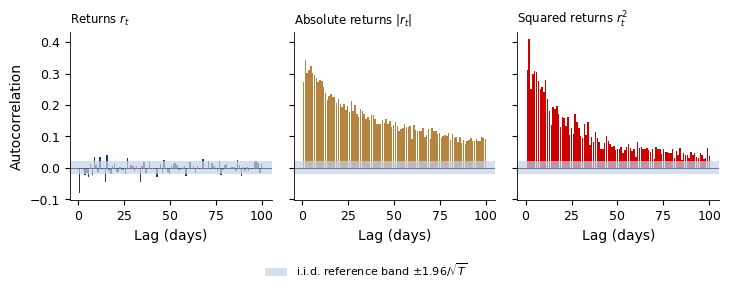

   saved ch1_acf_sp500


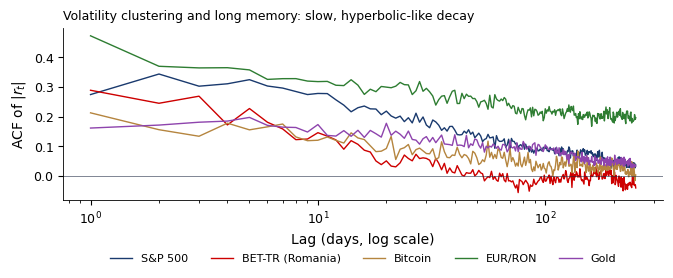

   saved ch1_acf_abs_assets
     sp500  bettr    btc  eurron   gold
1    0.274  0.289  0.213   0.472  0.161
5    0.324  0.227  0.155   0.357  0.197
20   0.218  0.051  0.093   0.299  0.178
100  0.093 -0.017  0.024   0.226  0.105
250  0.037 -0.040  0.003   0.196  0.032


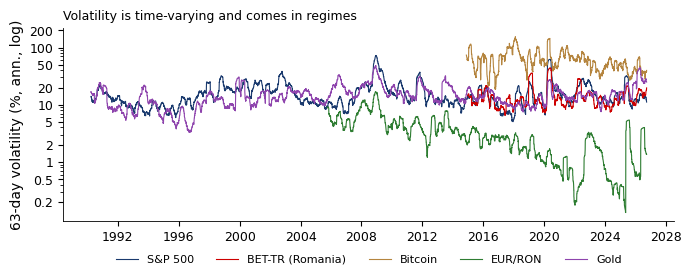

   saved ch1_rolling_vol


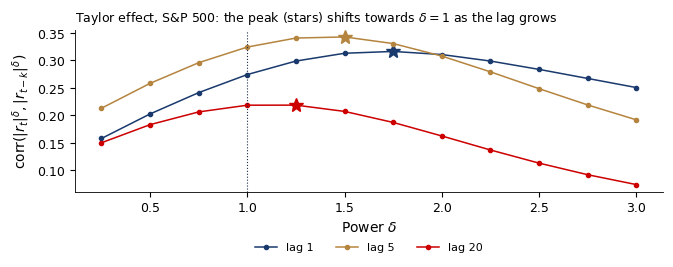

   saved ch1_taylor_effect
         1      5      20
0.25  0.158  0.213  0.150
0.50  0.203  0.258  0.183
0.75  0.241  0.296  0.206
1.00  0.274  0.324  0.218
1.25  0.299  0.341  0.219
1.50  0.313  0.343  0.207
1.75  0.316  0.331  0.187
2.00  0.311  0.308  0.162
2.25  0.299  0.279  0.137
2.50  0.284  0.249  0.113
2.75  0.267  0.219  0.092
3.00  0.251  0.192  0.074


In [ ]:
fig_acf_sp500()
print(fig_acf_abs_assets().loc[[1, 5, 20, 100, 250]].round(3))
fig_rolling_vol()
print(fig_taylor().round(3))

![ch1_acf_sp500](./ch1_acf_sp500.png)

Output: `ch1_acf_sp500.pdf`

![ch1_acf_abs_assets](./ch1_acf_abs_assets.png)

Output: `ch1_acf_abs_assets.pdf`

![ch1_rolling_vol](./ch1_rolling_vol.png)

Output: `ch1_rolling_vol.pdf`

![ch1_taylor_effect](./ch1_taylor_effect.png)

Output: `ch1_taylor_effect.pdf`